In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

import warnings
warnings.filterwarnings('ignore')

In [2]:
from google.colab import files

uploaded = files.upload()

Saving data.csv to data.csv


In [3]:
df = pd.read_csv('data.csv')

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
df.shape

(569, 33)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [7]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [8]:
df = df.drop(columns=['id', 'Unnamed: 32'], errors='ignore')
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [9]:
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})
df['diagnosis'].value_counts()

,count
diagnosis,
0,357
1,212


In [10]:
X = df.drop('diagnosis', axis=1)

y = df['diagnosis']

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [13]:
y = df['diagnosis']

x = df.drop('diagnosis', axis=1)

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

dt = DecisionTreeClassifier(random_state=42)

dt.fit(x_train, y_train)

y_train_pred = dt.predict(x_train)
y_test_pred = dt.predict(x_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 1.0
Testing Accuracy: 0.9298245614035088


In [15]:
print("Difference between Training and Testing Accuracy:",
      train_accuracy - test_accuracy)

Difference between Training and Testing Accuracy: 0.07017543859649122


In [16]:
dt_underfit = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

dt_underfit.fit(x_train, y_train)

underfit_train = accuracy_score(
    y_train,
    dt_underfit.predict(x_train)
)

underfit_test = accuracy_score(
    y_test,
    dt_underfit.predict(x_test)
)

print("Underfitting Model")
print("Training Accuracy:", underfit_train)
print("Testing Accuracy:", underfit_test)

Underfitting Model
Training Accuracy: 0.9296703296703297
Testing Accuracy: 0.8771929824561403


In [17]:
max_depth=1

In [18]:
depths = range(1, 16)

train_scores = []
test_scores = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(x_train, y_train)

    train_scores.append(
        accuracy_score(y_train, model.predict(x_train))
    )

    test_scores.append(
        accuracy_score(y_test, model.predict(x_test))
    )

print("Experiment completed!")

Experiment completed!


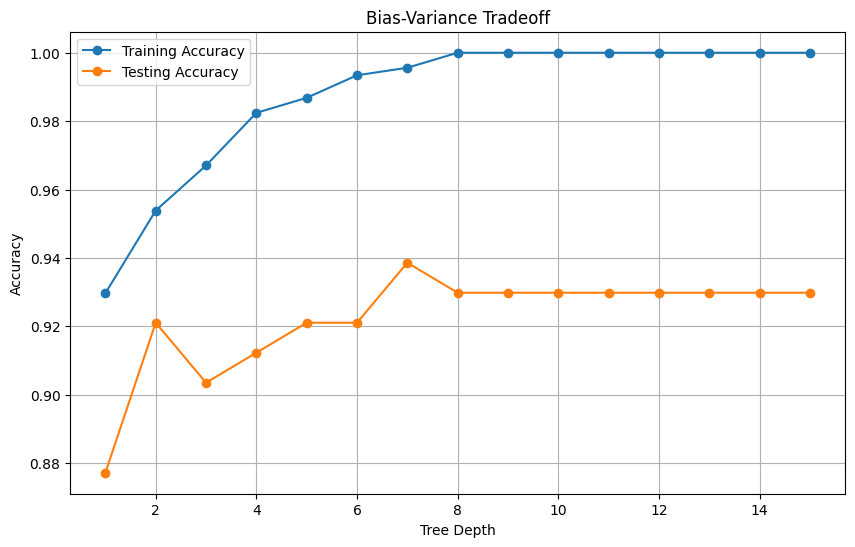

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    depths,
    train_scores,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    depths,
    test_scores,
    marker='o',
    label='Testing Accuracy'
)

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title("Bias-Variance Tradeoff")
plt.legend()
plt.grid()

plt.show()

In [20]:
from sklearn.ensemble import BaggingClassifier

bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42
)

bagging.fit(x_train, y_train)

bagging_train_pred = bagging.predict(x_train)
bagging_test_pred = bagging.predict(x_test)

print("Bagging Training Accuracy:",
      accuracy_score(y_train, bagging_train_pred))

print("Bagging Testing Accuracy:",
      accuracy_score(y_test, bagging_test_pred))

Bagging Training Accuracy: 1.0
Bagging Testing Accuracy: 0.9736842105263158


In [21]:
n_estimators=100

In [22]:
print("Decision Tree Testing Accuracy:",
      test_accuracy)

print("Bagging Testing Accuracy:",
      accuracy_score(y_test, bagging_test_pred))

Decision Tree Testing Accuracy: 0.9298245614035088
Bagging Testing Accuracy: 0.9736842105263158


In [23]:
!pip install xgboost -q

In [24]:
from xgboost import XGBClassifier

In [25]:
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [26]:
xgb_train_pred = xgb_model.predict(x_train)
xgb_test_pred = xgb_model.predict(x_test)

xgb_train_accuracy = accuracy_score(
    y_train,
    xgb_train_pred
)

xgb_test_accuracy = accuracy_score(
    y_test,
    xgb_test_pred
)

print("XGBoost Training Accuracy:", xgb_train_accuracy)
print("XGBoost Testing Accuracy:", xgb_test_accuracy)

XGBoost Training Accuracy: 1.0
XGBoost Testing Accuracy: 0.9649122807017544


In [27]:
n_estimators=100

In [28]:
learning_rate=0.1

In [29]:
max_depth=3

In [30]:
!pip install lightgbm -q

In [31]:
import lightgbm as lgb

In [32]:
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    num_leaves=15,
    random_state=42,
    verbosity=-1
)

lgb_model.fit(x_train, y_train)

LGBMClassifier(learning_rate=0.05, max_depth=3, num_leaves=15, random_state=42,
               verbosity=-1)

In [33]:
lgb_train_pred = lgb_model.predict(x_train)
lgb_test_pred = lgb_model.predict(x_test)

lgb_train_accuracy = accuracy_score(
    y_train,
    lgb_train_pred
)

lgb_test_accuracy = accuracy_score(
    y_test,
    lgb_test_pred
)

print("LightGBM Training Accuracy:", lgb_train_accuracy)
print("LightGBM Testing Accuracy:", lgb_test_accuracy)

LightGBM Training Accuracy: 1.0
LightGBM Testing Accuracy: 0.956140350877193


In [34]:
results = {
    "Decision Tree": test_accuracy,
    "Bagging": accuracy_score(y_test, bagging_test_pred),
    "XGBoost": xgb_test_accuracy,
    "LightGBM": lgb_test_accuracy
}

for model, accuracy in results.items():
    print(model, ":", accuracy)

Decision Tree : 0.9298245614035088
Bagging : 0.9736842105263158
XGBoost : 0.9649122807017544
LightGBM : 0.956140350877193


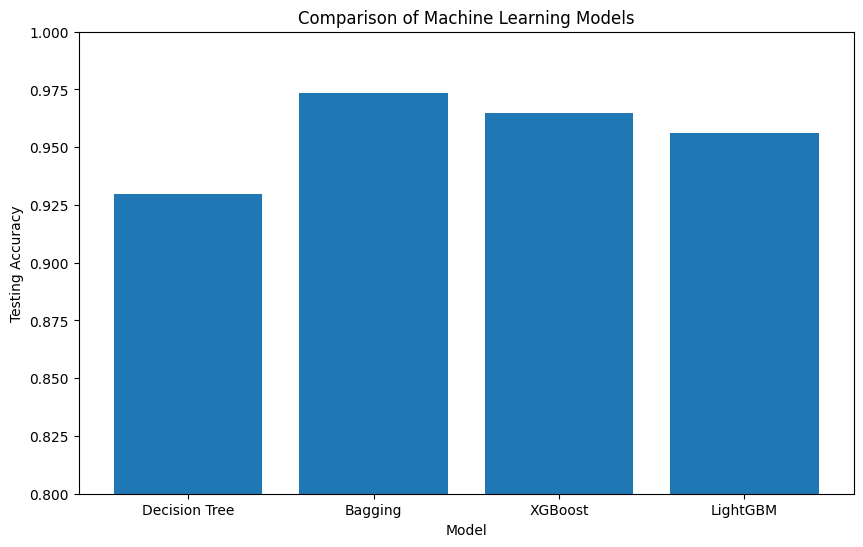

In [35]:
plt.figure(figsize=(10, 6))

plt.bar(
    results.keys(),
    results.values()
)

plt.xlabel("Model")
plt.ylabel("Testing Accuracy")
plt.title("Comparison of Machine Learning Models")

plt.ylim(0.8, 1.0)
plt.show()

In [36]:
xgb_overfit = XGBClassifier(
    n_estimators=500,
    learning_rate=0.2,
    max_depth=10,
    random_state=42,
    eval_metric='logloss'
)

xgb_overfit.fit(x_train, y_train)

overfit_train_accuracy = accuracy_score(
    y_train,
    xgb_overfit.predict(x_train)
)

overfit_test_accuracy = accuracy_score(
    y_test,
    xgb_overfit.predict(x_test)
)

print("Overfitted XGBoost")
print("Training Accuracy:", overfit_train_accuracy)
print("Testing Accuracy:", overfit_test_accuracy)

Overfitted XGBoost
Training Accuracy: 1.0
Testing Accuracy: 0.9736842105263158


In [37]:
xgb_regularized = XGBClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    min_child_weight=3,
    reg_alpha=0.1,
    reg_lambda=1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

xgb_regularized.fit(x_train, y_train)

regularized_train_accuracy = accuracy_score(
    y_train,
    xgb_regularized.predict(x_train)
)

regularized_test_accuracy = accuracy_score(
    y_test,
    xgb_regularized.predict(x_test)
)

print("Regularized XGBoost")
print("Training Accuracy:", regularized_train_accuracy)
print("Testing Accuracy:", regularized_test_accuracy)

Regularized XGBoost
Training Accuracy: 0.989010989010989
Testing Accuracy: 0.9736842105263158


In [38]:
comparison = pd.DataFrame({
    "Model": [
        "Overfitted XGBoost",
        "Regularized XGBoost"
    ],
    "Training Accuracy": [
        overfit_train_accuracy,
        regularized_train_accuracy
    ],
    "Testing Accuracy": [
        overfit_test_accuracy,
        regularized_test_accuracy
    ]
})

comparison

,Model,Training Accuracy,Testing Accuracy
0,Overfitted XGBoost,1.000000,0.973684
1,Regularized XGBoost,0.989011,0.973684


In [39]:
print("Regularization parameters used:")
print("max_depth = 3")
print("min_child_weight = 3")
print("reg_alpha = 0.1")
print("reg_lambda = 1")
print("subsample = 0.8")
print("colsample_bytree = 0.8")

Regularization parameters used:
max_depth = 3
min_child_weight = 3
reg_alpha = 0.1
reg_lambda = 1
subsample = 0.8
colsample_bytree = 0.8


In [40]:
final_results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Bagging",
        "XGBoost",
        "LightGBM",
        "Regularized XGBoost"
    ],
    "Testing Accuracy": [
        test_accuracy,
        accuracy_score(y_test, bagging_test_pred),
        xgb_test_accuracy,
        lgb_test_accuracy,
        regularized_test_accuracy
    ]
})

final_results

,Model,Testing Accuracy
0,Decision Tree,0.929825
1,Bagging,0.973684
2,XGBoost,0.964912
3,LightGBM,0.956140
4,Regularized XGBoost,0.973684


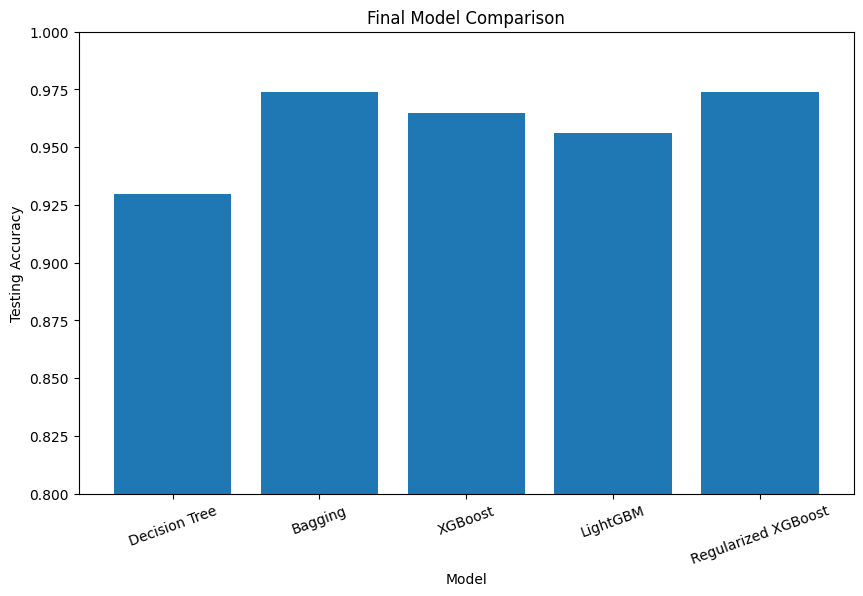

In [41]:
plt.figure(figsize=(10, 6))

plt.bar(
    final_results["Model"],
    final_results["Testing Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Testing Accuracy")
plt.title("Final Model Comparison")

plt.ylim(0.8, 1.0)
plt.xticks(rotation=20)

plt.show()

In [42]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        xgb_model.predict(x_test),
        target_names=["Benign", "Malignant"]
    )
)

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



In [43]:
print(
    classification_report(
        y_test,
        lgb_model.predict(x_test),
        target_names=["Benign", "Malignant"]
    )
)

              precision    recall  f1-score   support

      Benign       0.94      1.00      0.97        72
   Malignant       1.00      0.88      0.94        42

    accuracy                           0.96       114
   macro avg       0.97      0.94      0.95       114
weighted avg       0.96      0.96      0.96       114

